# LAB — Vision-Language Models: CLIP & LLaVA

**Module:** Artificial Intelligence / Generative AI  
**Level:** Phd Students  
**Environment:** Google Colab / Kaggle / Jupyter Notebook  
**Frameworks:** Python, PyTorch, Hugging Face Transformers

## Videos (Must see before Starting the Lab)
* https://www.youtube.com/watch?v=jXD6O93Ptks&t=6s
* https://www.youtube.com/watch?v=bK9ns4DkxQg&t=8s

## Objectives

This practical work introduces two important vision-language models:

- **CLIP**: image-text representation, similarity, zero-shot classification and image retrieval.
- **LLaVA**: multimodal image understanding and visual question answering.

At the end of the Lab, students should be able to:
1. Load a pretrained CLIP model.
2. Compare images and textual descriptions.
3. Perform zero-shot classification.
4. Evaluate classification accuracy.
5. Perform text-to-image retrieval.
6. Understand the architecture of LLaVA.
7. Run visual question answering.
8. Identify visual hallucinations.
9. Compare CLIP and LLaVA.
10. Build a small multimodal assistant.

> **Notebook organization:** Part I is the student statement. Part II contains the correction and reference implementations. Students should first complete the exercises without opening the correction section.

# Part I — LAB STATEMENT

## Exercise 1 — Installation and model loading

Install the required libraries and load `openai/clip-vit-base-patch32`.

### Questions

**Q1.** What is CLIP?  
**Q2.** What are its two main components?  
**Q3.** What is the role of `CLIPProcessor`?  
**Q4.** What is the role of `CLIPModel`?

### Q1. What is CLIP?

CLIP (Contrastive Language–Image Pre-training) is a vision-language model developed by OpenAI. It learns to associate images with their corresponding textual descriptions.

### Q2. What are its two main components?

CLIP has two main components:
- **Image encoder:** extracts visual features from an image.
- **Text encoder:** extracts semantic features from a text description.

Both encoders map images and text into a shared embedding space.

### Q3. What is the role of `CLIPProcessor`?

`CLIPProcessor` prepares images and text before they are passed to the model. It preprocesses images, tokenizes text, and returns tensors in the format expected by CLIP.

### Q4. What is the role of `CLIPModel`?

`CLIPModel` contains the pretrained image and text encoders. It generates image and text embeddings and calculates similarity scores between images and textual descriptions.

In [ ]:
# Run this cell first.
!pip install -q transformers torch torchvision pillow matplotlib pandas

In [ ]:
import torch
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

Device: cpu


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## Exercise 2 — Load an image

Upload an image containing a recognizable object.

Examples: a cat, dog, car, horse, bird, airplane, person, etc.

### Questions

**Q5.** What is the size of the image?  
**Q6.** What type of data is stored in the PIL image object?

### Q5. What is the size of the image?

The image size is **960 × 1282 pixels**, where 960 is the width and 1282 is the height.

### Q6. What type of data is stored in the PIL image object?

A PIL image object stores image pixel data and metadata, such as its dimensions and color mode. In this experiment, the image is converted to RGB, which represents each pixel using three color channels: red, green, and blue.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Cat.jpg to Cat (1).jpg


Image size: (960, 1282)
Image mode: RGB


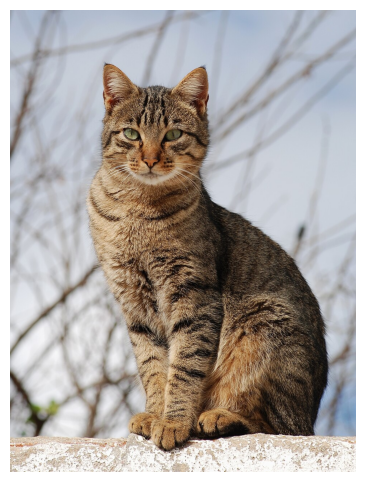

In [ ]:
# Upload an image in Google Colab/Jupyter and change the filename if necessary.

from PIL import Image
import matplotlib.pyplot as plt

IMAGE_PATH =next(iter(uploaded.keys()))

image = Image.open(IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
print("Image mode:", image.mode)

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off");

## Exercise 3 — Image/Text similarity

Use the following textual descriptions:

```python
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]
```

Calculate the CLIP image-text scores and convert them to probabilities.

### Questions

**Q7.** Which description has the highest probability?  
**Q8.** Is it compatible with the actual image?  
**Q9.** Why can CLIP compare an image with a sentence?  
**Q10.** What does `softmax()` do?

### Q7. Which description has the highest probability?

The description **“a photo of a cat”** has the highest probability, approximately 99.39%.

### Q8. Is it compatible with the actual image?

Yes, the prediction is compatible with the actual image because the image contains a cat, and CLIP assigns the highest probability to the cat description.

### Q9. Why can CLIP compare an image with a sentence?

CLIP uses separate image and text encoders that map images and sentences into a shared embedding space. It compares their embeddings to measure how closely an image matches a text description.

### Q10. What does `softmax()` do?

The `softmax()` function converts a vector of scores into normalized values between 0 and 1 that sum to 1. These values represent relative probabilities among the candidate descriptions, but they are not necessarily calibrated real-world probabilities.

In [ ]:
texts = [
    "a photo of a cat",
    "a photo of a dog",
    "a photo of a car",
    "a photo of a horse",
    "a photo of a person"
]

inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for text, probability in zip(texts, probs):
    print(f"{text:35s}: {probability.item():.4f}")

a photo of a cat                   : 0.9939
a photo of a dog                   : 0.0026
a photo of a car                   : 0.0001
a photo of a horse                 : 0.0003
a photo of a person                : 0.0031


## Exercise 4 — Zero-shot classification

Implement:

```python
def classify_image(image, classes):
    ...
```

The function must return the predicted class and its probability.

### Questions

**Q11.** What is zero-shot classification?  
**Q12.** Why is it not necessary to train a new classifier?  
**Q13.** What happens if the correct class is not included in the candidate classes?

### Q11. What is zero-shot classification?

Zero-shot classification is a technique that allows a model to classify an image into one of several candidate classes without being specifically trained on those classes for the current task.

### Q12. Why is it not necessary to train a new classifier?

It is not necessary to train a new classifier because CLIP has already learned relationships between images and text during pretraining. It compares the image with textual descriptions of the candidate classes and selects the class with the highest similarity score.

### Q13. What happens if the correct class is not included in the candidate classes?

If the correct class is not included, CLIP will select the most similar class among the available candidates, even if that prediction is incorrect. Therefore, the candidate classes should cover the possible contents of the image.

In [ ]:
# STUDENT TASK
def classify_image(image, classes):
  inputs=processor(
      text=[f"a photo of a {c}"for c in classes],
      images=image,
      return_tensors="pt",
      padding=True
  )
  inputs = {k: v.to(device) for k, v in inputs.items()}

  with torch.no_grad():
    outputs = model(**inputs)

  probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()
  best_idx = probs.argmax().item()

  return classes[best_idx], probs[best_idx].item()

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]

prediction, probability = classify_image(image, classes)

print("Prediction:", prediction)
print("Probability:", probability)

Prediction: cat
Probability: 0.996367335319519


## Exercise 5 — Evaluate CLIP

Prepare at least 10 labeled images. For each image record:

- actual class;
- predicted class;
- probability;
- whether the prediction is correct.

Calculate:


$Accuracy = \frac{N_{correct}}{N_{total}}$


### Questions

**Q14.** What is the obtained accuracy?  
**Q15.** Which images are incorrectly classified?  
**Q16.** Give at least two possible reasons for the errors.

Use the following format:

```python
dataset = [
    ("cat1.jpg", "cat"),
    ("cat2.jpg", "cat"),
    ...
]
```

**Q14. What is the obtained accuracy?**

The obtained accuracy is **100%**. CLIP correctly classified all 10 labeled images.

$$
\text{Accuracy} = \frac{N_{\text{correct}}}{N_{\text{total}}}
= \frac{10}{10} = 1.0 = 100\%
$$

**Q15. Which images are incorrectly classified?**

No images were incorrectly classified. All 10 images were assigned the correct class: cat, car, bird, horse, or airplane.

**Q16. Give at least two possible reasons for the errors.**

Although no classification errors occurred in this experiment, possible reasons for errors in other images include:

1. **Visual ambiguity:** Different classes may have similar visual features, making them difficult to distinguish.
2. **Image quality:** Poor lighting, low resolution, unusual viewpoints, or complex backgrounds may affect classification.
3. **Prompt wording:** The text descriptions used for candidate classes may not accurately represent the image.

These factors may reduce CLIP's classification accuracy on more challenging images.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving animal2.jpg to animal2.jpg
Saving animal.webp to animal.webp
Saving sport2.jpg to sport2.jpg
Saving sport.jpg to sport.jpg
Saving people2.jpeg to people2.jpeg
Saving people.jpg to people.jpg
Saving landscape3.jpg to landscape3.jpg
Saving landscape2.webp to landscape2.webp
Saving landscape.jpg to landscape.jpg
Saving food.jpeg to food.jpeg
Saving Building.jpeg to Building.jpeg
Saving Airplane2.jpeg to Airplane2.jpeg
Saving Airplane.jpeg to Airplane.jpeg
Saving Horse2.jpg to Horse2.jpg
Saving Horse.jpeg to Horse.jpeg
Saving Bird2.jpg to Bird2.jpg
Saving Bird1.jpg to Bird1.jpg
Saving Car2.jpg to Car2.jpg
Saving Car1.jpg to Car1.jpg
Saving Cat2.jpg to Cat2.jpg


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'animal.webp', 'Bird2.jpg', 'Airplane.jpeg', 'people2.jpeg', 'landscape2.webp', 'Car1.jpg', 'Airplane2.jpeg', 'Cat.jpg', 'animal2.jpg', 'food.jpeg', 'Horse2.jpg', 'Building.jpeg', 'landscape.jpg', 'Cat2.jpg', 'Horse.jpeg', 'sport2.jpg', 'Car2.jpg', 'people.jpg', 'Bird1.jpg', 'Cat (1).jpg', 'sport.jpg', 'landscape3.jpg', 'sample_data']


In [ ]:
dataset = [
    ("Cat.jpg","cat"),
    ("Cat2.jpg", "cat"),
    ("Car1.jpg","car"),
    ("Car2.jpg","car"),
    ("Bird1.jpg","bird"),
    ("Bird2.jpg","bird"),
    ("Horse.jpeg","horse"),
    ("Horse2.jpg","horse"),
    ("Airplane.jpeg","airplane"),
    ("Airplane2.jpeg","airplane"),
]
print("Number of labeled images:", len(dataset))

Number of labeled images: 10


In [ ]:
import pandas as pd
from PIL import Image
import os

classes = ["cat", "dog", "car", "airplane", "horse", "bird"]
results = []

for filename,actual_class in dataset:
  img = Image.open(
      os.path.join("/content", filename)
  ).convert("RGB")

  prediction, probability = classify_image(img,classes)


  results.append({
      "Image": filename,
      "Actual_class": actual_class,
      "predicted_class": prediction,
      "Probability": round(probability, 4),
      "Correct": prediction ==actual_class
  })
df = pd.DataFrame(results)
display(df)

accurarcy = df["Correct"].mean() * 100
print(f"Accuracy:{accurarcy:.2f}%")

print("\nIncorrectly classified images:")
display(df[df["Correct"] == False])


,Image,Actual_class,predicted_class,Probability,Correct
0,Cat.jpg,cat,cat,0.9964,True
1,Cat2.jpg,cat,cat,0.9882,True
2,Car1.jpg,car,car,0.9965,True
3,Car2.jpg,car,car,0.9963,True
4,Bird1.jpg,bird,bird,0.9992,True
5,Bird2.jpg,bird,bird,0.9983,True
6,Horse.jpeg,horse,horse,0.9993,True
7,Horse2.jpg,horse,horse,0.9989,True
8,Airplane.jpeg,airplane,airplane,0.9962,True
9,Airplane2.jpeg,airplane,airplane,0.9627,True


Accuracy:100.00%

Incorrectly classified images:


,Image,Actual_class,predicted_class,Probability,Correct


In [ ]:
from PIL import Image
import os

classes =["cat", "dog", "car", "airplane", "horse", "bird"]

for filename in ["Cat.jpg", "Car1.jpg"]:
  path = os.path.join("/content", filename)
  img = Image.open(path).convert("RGB")

  prediction, probability = classify_image(img, classes)
  print("Image:", filename)
  print("Prediction:", prediction)
  print("Probability:", round(probability, 4))
  print("-" *30)

Image: Cat.jpg
Prediction: cat
Probability: 0.9964
------------------------------
Image: Car1.jpg
Prediction: car
Probability: 0.9965
------------------------------


## Exercise 6 — Prompt engineering with CLIP

Compare:

```python
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]
```

### Questions

**Q17.** Are the scores identical?  
**Q18.** Which prompt gives the highest score?  
**Q19.** What does this demonstrate about prompt formulation?

**Q17. Are the scores identical?**

No, the scores are different for each prompt. The similarity scores range from 0.0374 to 0.5421.

**Q18. Which prompt gives the highest score?**

The prompt **"a photograph showing a cat"** gives the highest score, with a similarity score of **0.5421**.

**Q19. What does this demonstrate about prompt formulation?**

This demonstrates that prompt formulation significantly affects CLIP's similarity scores. Different descriptions of the same concept can produce different results, and a more descriptive prompt may provide a stronger semantic match to the image.

In [ ]:
# STUDENT TASK
prompts = [
    "a cat",
    "a photo of a cat",
    "a photograph showing a cat",
    "an image containing a cat",
    "a domestic animal called a cat"
]

inputs = processor(
    text=prompts,
    images=image,
    return_tensors="pt",
    padding=True
)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

probs = outputs.logits_per_image.softmax(dim=1)[0].cpu()

for prompt, score in zip(prompts, probs):
    print(f"{prompt:35s}: {score.item():.4f}")

# Calculate and compare the scores for all prompts.

a cat                              : 0.0374
a photo of a cat                   : 0.1877
a photograph showing a cat         : 0.5421
an image containing a cat          : 0.0675
a domestic animal called a cat     : 0.1652


# Part B — CLIP Image Retrieval

## Exercise 7 — Build an image database

Create a folder containing at least 20 images.

The images can represent animals, vehicles, people, buildings, landscapes, food or sports.

Calculate and store a normalized CLIP embedding for every image.

## Exercise 8 — Text-to-image retrieval

Use the query:

```text
"a person playing football"
```

Calculate its text embedding, compare it with all image embeddings, and display the five most similar images.

### Questions

**Q20.** What is the most similar image?  
**Q21.** Is it semantically relevant?  
**Q22.** Why does this method not require image labels?  
**Q23.** Give one real-world application of semantic image retrieval.

**Q20. What is the most similar image?**

The most similar image is the picture of football players, ranked first with a similarity score of **0.249**.

**Q21. Is it semantically relevant?**

Yes, it is semantically relevant because the image shows children playing football, which matches the query *"a person playing football"*.

**Q22. Why does this method not require image labels?**

This method does not require image labels because CLIP compares the text query embedding with image embeddings in a shared vector space. Images are ranked according to semantic similarity rather than predefined labels.

**Q23. Give one real-world application of semantic image retrieval.**

One real-world application is searching a large photo collection using natural-language descriptions, such as *"a person playing football"*, without manually labeling every image.

In [ ]:
import os

image_extensions = (".jpg", ".jpeg", ".png", ".webp")

image_files =[
    f for f in os.listdir("/content")
    if f.lower().endswith(image_extensions)
]

print("Number of images:", len(image_files))

for filename in sorted(image_files):
    print(filename)

Number of images: 22
Airplane.jpeg
Airplane2.jpeg
Bird1.jpg
Bird2.jpg
Building.jpeg
Car1.jpg
Car2.jpg
Cat (1).jpg
Cat.jpg
Cat2.jpg
Horse.jpeg
Horse2.jpg
animal.webp
animal2.jpg
food.jpeg
landscape.jpg
landscape2.webp
landscape3.jpg
people.jpg
people2.jpeg
sport.jpg
sport2.jpg


In [ ]:
# STUDENT TASK
# 1. Put your images in IMAGE_DIR.
# 2. Compute image embeddings.
# 3. Compute the query embedding.
# 4. Calculate cosine similarity.
# 5. Display Top-5 images.
import os
import shutil

IMAGE_DIR = "/content/images"
os.makedirs(IMAGE_DIR, exist_ok=True)

extensions = (".jpg", ".jpeg", ".png", ".webp")
count = 0

for filename in os.listdir("/content"):
  source = os.path.join("/content", filename)

  if os.path.isfile(source) and filename.lower().endswith(extensions):
    destination = os.path.join(IMAGE_DIR, filename)

    if not os.path.exists(destination):
      shutil.move(source, destination)
      count += 1

print("Images moved:", count)
print("Total images in folder:", len([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(extensions)
]))
print("Folder:", IMAGE_DIR)

Images moved: 22
Total images in folder: 22
Folder: /content/images


In [ ]:
import os
import torch.nn.functional as F
from PIL import Image

IMAGE_DIR = "/content/images"

image_paths = sorted([
    os.path.join(IMAGE_DIR, f)
    for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])
image_embeddings = []

for path in image_paths:
  img = Image.open(path).convert("RGB")

  inputs = processor(images=img, return_tensors="pt")
  inputs = {k: v.to(device) for k, v in inputs.items()}

  with torch.no_grad():
    features = model.get_image_features(**inputs)

    if hasattr(features, "pooler_output"):
      features = features.pooler_output
    elif hasattr(features, "image_embeds"):
      features = features.iamge_embeds
    features = F.normalize(features, p=2, dim=-1)
    image_embeddings.append(features.cpu())
image_embeddings = torch.cat(image_embeddings, dim=0)



print("Images processed:", len(image_paths))
print("Embedding matrix shape:", image_embeddings.shape)


Images processed: 22
Embedding matrix shape: torch.Size([22, 512])


In [ ]:
QUERY = "a person playing football"

inputs = processor(
    text=[Query],
    return_tensors="pt",
    padding=True
)

inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
  text_features = model.get_text_features(**inputs)

if hasattr(text_features, "pooler_output"):
  text_features = text_features.pooler_output
elif hasattr(text_features, "text_embeds"):
  text_features = text_features.text_embeds

text_features = F.normalize(text_features, p=2, dim=-1).cpu()

print("Query:", QUERY)
print("Text Embedding shape:", text_features.shape)

Query: a person playing football
Text Embedding shape: torch.Size([1, 512])


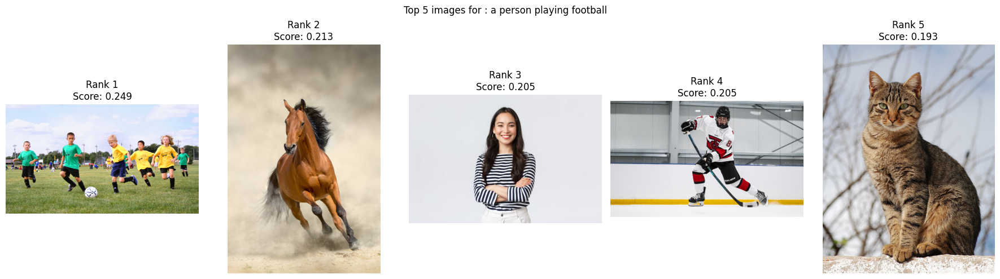

In [ ]:
import matplotlib.pyplot as plt
import torch

similarities = image_embeddings @ text_features.T
similarities = similarities.squeeze(1)

top_indices = torch.topk(similarities, k=5).indices

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for rank, idx in enumerate(top_indices):
  i = idx.item()
  img = Image.open(image_paths[i]).convert("RGB")

  axes[rank].imshow(img)
  axes[rank].set_title(
      f"Rank {rank + 1}\nScore: {similarities[i].item():.3f}"
  )
  axes[rank].axis("off")

plt.suptitle(f"Top 5 images for : {QUERY}")
plt.tight_layout()
plt.show()


















# Part C — LLaVA

## Exercise 9 — Architecture

Complete:

```text
Image
  |
  v
CLIP Vision Encoder
  |
  v
Projection Layer
  |
  v
Language Model
  |
  v
Text Response
```

### Questions

**Q24.** What is the role of the vision encoder?  
**Q25.** Why is a projection layer required?  
**Q26.** What is the role of the language model?

**Q24. What is the role of the vision encoder?**

The vision encoder extracts visual features from the input image and converts them into a numerical representation that captures its visual content.

**Q25. Why is a projection layer required?**

The projection layer maps the visual features into the embedding space and dimension expected by the language model, allowing the visual information to be used as input to the language model.

**Q26. What is the role of the language model?**

The language model processes the visual information together with the text prompt to generate a natural-language response about the image.

## Exercise 10 — Run LLaVA

Use a LLaVA-compatible model appropriate for your available GPU.

Give the model an image and ask:

1. What is happening in this image?
2. How many people are visible?
3. What objects can you identify?
4. Describe the image in detail.

Record the answers.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving images_backup.zip to images_backup.zip


In [ ]:
import os
import zipfile

zip_path = "/content/images_backup.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
  zip_ref.extractall("/content/images")
print("Images restaurees: ", len(os.listdir("/content/images")))

Images restaurees:  22


In [ ]:
image_paths = sorted([
    os.path.join("/content/images", f)
    for f in os.listdir("/content/images")
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])

print("Nombre d'images:", len(image_paths))

Nombre d'images: 22


In [ ]:
print("Nombre d'images:", len(image_paths))
print("Premiere image:", image_paths[0])

Nombre d'images: 22
Premiere image: /content/images/Airplane.jpeg


In [ ]:
from PIL import Image

image = Image.open(image_paths[0]).convert("RGB")

question  = "What is happening in this image?"

prompt = f"USER: <image>\n{question} ASSISATANT:"

inputs = processor_llava(
    text=prompt,
    images=image,
    return_tensors="pt"
).to("cuda", torch.float16)

with torch.inference_mode():
  output = llava.generate(
      **inputs,
      max_new_tokens=150
  )
answer = processor_llava.decode(
    output[0],
    skip_special_tokens=True
)
print(answer)

USER:  
What is happening in this image? ASSISATANT: In the image, a large white airplane is flying through the sky.


In [ ]:
questions = [
    "What is happening in this image?",
    "How many people are visible?",
    "What objects can you identify?",
    "Describe the image in detail."
]

results  = []

for question in questions :
  prompt = f"USER: <image>\n{question} ASSISTANT:"

  inputs = processor_llava(
      text=prompt,
      images=image,
      return_tensors="pt"
  ).to("cuda", torch.float16)
  with torch.inference_mode():
    output = llava.generate(
        **inputs,
        max_new_tokens=150
    )
  answer = processor_llava.decode(
      output[0],
      skip_special_tokens=True
  )
  results.append({
      "question": question,
      "answer": answer
  })
  print("Question : ", question)
  print("Answer : ", answer)
  print("-" * 50)

Question :  What is happening in this image?
Answer :  USER:  
What is happening in this image? ASSISTANT: In the image, a large white airplane is flying through the sky. It appears to be a commercial jet, and the airplane is flying in a clear blue sky.
--------------------------------------------------
Question :  How many people are visible?
Answer :  USER:  
How many people are visible? ASSISTANT: There are no people visible in the image.
--------------------------------------------------
Question :  What objects can you identify?
Answer :  USER:  
What objects can you identify? ASSISTANT: In the image, you can identify a large white airplane flying in the sky. The airplane has a distinctive shape, and its wings are clearly visible. The scene also features a cloudy blue sky, which provides a backdrop for the airplane's flight.
--------------------------------------------------
Question :  Describe the image in detail.
Answer :  USER:  
Describe the image in detail. ASSISTANT: The im

In [ ]:
with open("/content/exercise10_answers.txt","w", encoding="utf-8") as f:
  for item in results:
    answer = item["answer"]
    if "ASSISTANT:" in answer:
      answer = answer.split("ASSISTANT:")[-1].strip()
    f.write("Question: " + item["question"] + "\n")
    f.write("Answer: " + answer + "\n\n")
print("Answers saved sucessfully !")

Answers saved sucessfully !


In [ ]:
from google.colab import files

files.download("/content/exercise10_answers.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
  print("GPU:", torch.cuda.get_device_name(0))
else:
  print("Running on CPU")

CUDA available: False
Running on CPU


In [ ]:
import os
import torch
import shutil

shutil.make_archive(
    "/content/images_backup",
    "zip",
    "/content/images"
)
print("Images backup:", os.path.exists("/content/images_backup.zip"))
if "image_embeddings" in globals():
  torch.save(
      {
          "image_paths": image_paths,
          "image_embeddings": image_embeddings.cpu()
      },
      "/content/clip_embeddings_backup.pt"
  )
  print("Embeddings backup saved:")
else:
  print("Image embeddings are not available")


Images backup: True
Embeddings backup saved:


In [ ]:
from google.colab import files

files.download("/content/images_backup.zip")
files.download("/content/clip_embeddings_backup.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
  print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [ ]:
import torch
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_ID = "openai/clip-vit-base-patch32"

processor = CLIPProcessor.from_pretrained(MODEL_ID)
model = CLIPModel.from_pretrained(MODEL_ID).to(device)
model.eval()

print("Device :", device)
print("CLIP model loaded successfully")

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Device : cuda
CLIP model loaded successfully


In [ ]:
!pip install -q transformers accelerate bitsandbytes

In [ ]:
import transformers
import accelerate
import bitsandbytes

print("Transformers version:", transformers.__version__)
print("Accelerate version:", accelerate.__version__)
print("Bitsandbytes version:", bitsandbytes.__version__)

Transformers version: 5.18.0
Accelerate version: 1.15.0
Bitsandbytes version: 0.50.2


In [ ]:
import torch

print("GPU available", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    "GB"
)

GPU available True
GPU: Tesla T4
GPU memory: 14.56 GB


In [ ]:
from transformers import LlavaForConditionalGeneration, AutoProcessor

print("LLaVA classes imported successfully")

LLaVA classes imported successfully


## Exercise 11 — Visual Question Answering

Choose five images. For each image ask five questions.

Example:

1. How many people are visible?
2. What objects can you see?
3. Where are the people?
4. What are they doing?
5. What is visible on the board?

Create a table containing:

| Image | Question | LLaVA Answer | Human Evaluation |
|---|---|---|---|

Calculate VQA accuracy:

\[
Accuracy = \frac{CorrectAnswers}{TotalQuestions}
\]

### Questions

**Q27.** What is the VQA accuracy?  
**Q28.** Which types of questions are difficult for LLaVA?

**Q27. What is the VQA accuracy?**

The VQA accuracy is **60%**. Out of 25 questions, 15 were answered correctly by LLaVA and 10 were answered incorrectly.

$$
\text{VQA Accuracy} = \frac{15}{25} \times 100 = 60%
$$

**Q28. Which types of questions are difficult for LLaVA?**

LLaVA may struggle with questions that require accurate spatial understanding, identifying relationships between people and objects, or interpreting details that are not clearly visible in an image. In this experiment, questions based on incorrect assumptions about the image, such as asking what people are doing when no people are visible, also led to incorrect answers.


In [ ]:
selected_images = image_paths[:5]
print("Number of selected images:", len(selected_images))

for path in selected_images:
  print(path)

Number of selected images: 5
/content/images/Airplane.jpeg
/content/images/Airplane2.jpeg
/content/images/Bird1.jpg
/content/images/Bird2.jpg
/content/images/Building.jpeg


In [ ]:
vqa_questions = [
    "How many people are visible?",
    "What objects can you see?",
    "Where are the people?",
    "What are they doing?",
    "What is visible in the background?"
]

In [ ]:
from PIL import Image

vqa_results = []

for path in selected_images:
  image = Image.open(path).convert("RGB")

  for question in vqa_questions:
    prompt = f"USER: <image>\n{question} ASSISTANT:"

    inputs = processor_llava(
        text=prompt,
        images=image,
        return_tensors="pt"
    ).to("cuda", torch.float16)

    with torch.inference_mode():
      output = llava.generate(
          **inputs,
          max_new_tokens=150
      )
    answer = processor_llava.decode(
        output[0],
        skip_special_tokens=True
    )
    if "ASSISTANT:" in answer:
      answer = answer.split("ASSISTANT:")[-1].strip()
    vqa_results.append({
        "image": path,
        "question": question,
        "answer": answer
    })
    print("Image:", path)
    print("Question:", question)
    print("Answer:", answer)
    print("-" * 50)

Image: /content/images/Airplane.jpeg
Question: How many people are visible?
Answer: There are no people visible in the image.
--------------------------------------------------
Image: /content/images/Airplane.jpeg
Question: What objects can you see?
Answer: I can see a large airplane flying in the sky.
--------------------------------------------------
Image: /content/images/Airplane.jpeg
Question: Where are the people?
Answer: The people are on the ground, watching the airplane flying in the sky.
--------------------------------------------------
Image: /content/images/Airplane.jpeg
Question: What are they doing?
Answer: The people in the image are flying a large jet airplane. They are likely pilots or crew members responsible for operating and managing the aircraft during its flight.
--------------------------------------------------
Image: /content/images/Airplane.jpeg
Question: What is visible in the background?
Answer: In the background, there is a blue sky visible.
--------------

In [ ]:
import pandas as pd

df_vqa = pd.DataFrame(vqa_results)

df_vqa.columns =["Image", "Question", "LLaVA Answer"]

df_vqa["Human Evaluation"] = ""

df_vqa

,Image,Question,LLaVA Answer,Human Evaluation
0,/content/images/Airplane.jpeg,How many people are visible?,There are no people visible in the image.,
1,/content/images/Airplane.jpeg,What objects can you see?,I can see a large airplane flying in the sky.,
2,/content/images/Airplane.jpeg,Where are the people?,"The people are on the ground, watching the air...",
3,/content/images/Airplane.jpeg,What are they doing?,The people in the image are flying a large jet...,
4,/content/images/Airplane.jpeg,What is visible in the background?,"In the background, there is a blue sky visible.",
5,/content/images/Airplane2.jpeg,How many people are visible?,There are no people visible in the image.,
6,/content/images/Airplane2.jpeg,What objects can you see?,"In the image, you can see a large airplane, sp...",
7,/content/images/Airplane2.jpeg,Where are the people?,The people are not visible in the image. They ...,
8,/content/images/Airplane2.jpeg,What are they doing?,The people in the image are flying a large jet...,
9,/content/images/Airplane2.jpeg,What is visible in the background?,"In the background, there is a cloudy sky.",


In [ ]:
correct_answers = (df_vqa["Human Evaluation"] == "Correct").sum()
total_questions = len(df_vqa)

accuracy = correct_answers / total_questions

print("Correct answers:", correct_answers)
print("Total questions:", total_questions)
print("VQA accuracy:", round(accuracy * 100, 2), "%")

Correct answers: 0
Total questions: 25
VQA accuracy: 0.0 %


In [ ]:
print(df_vqa.head())
print(df_vqa.keys())

                           Image                            Question  \
0  /content/images/Airplane.jpeg        How many people are visible?   
1  /content/images/Airplane.jpeg           What objects can you see?   
2  /content/images/Airplane.jpeg               Where are the people?   
3  /content/images/Airplane.jpeg                What are they doing?   
4  /content/images/Airplane.jpeg  What is visible in the background?   

                                        LLaVA Answer Human Evaluation  
0          There are no people visible in the image.                   
1      I can see a large airplane flying in the sky.                   
2  The people are on the ground, watching the air...                   
3  The people in the image are flying a large jet...                   
4    In the background, there is a blue sky visible.                   
Index(['Image', 'Question', 'LLaVA Answer', 'Human Evaluation'], dtype='object')


In [ ]:
display(df_vqa[["Image", "Question", "LLaVA Answer", "Human Evaluation"]])

,Image,Question,LLaVA Answer,Human Evaluation
0,/content/images/Airplane.jpeg,How many people are visible?,There are no people visible in the image.,
1,/content/images/Airplane.jpeg,What objects can you see?,I can see a large airplane flying in the sky.,
2,/content/images/Airplane.jpeg,Where are the people?,"The people are on the ground, watching the air...",
3,/content/images/Airplane.jpeg,What are they doing?,The people in the image are flying a large jet...,
4,/content/images/Airplane.jpeg,What is visible in the background?,"In the background, there is a blue sky visible.",
5,/content/images/Airplane2.jpeg,How many people are visible?,There are no people visible in the image.,
6,/content/images/Airplane2.jpeg,What objects can you see?,"In the image, you can see a large airplane, sp...",
7,/content/images/Airplane2.jpeg,Where are the people?,The people are not visible in the image. They ...,
8,/content/images/Airplane2.jpeg,What are they doing?,The people in the image are flying a large jet...,
9,/content/images/Airplane2.jpeg,What is visible in the background?,"In the background, there is a cloudy sky.",


In [ ]:
df-vqa["Human Evaluation"]  = ""

SyntaxError: cannot assign to expression here. Maybe you meant '==' instead of '='? (4107551593.py, line 1)

In [ ]:

print("df_vqa: ", "df_vqa " in globals())
print("vqa_results: ", "vqa_results" in globals())
print("llava:", "llava" in globals())

df_vqa:  False
vqa_results:  False
llava: False


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving images_backup.zip to images_backup.zip


In [ ]:
import zipfile
import os

with zipfile.ZipFile("/content/images_backup.zip", "r") as z:
  z.extractall("/content/images")
print("Images disponibles: ", len(os.listdir("/content/images")))

Images disponibles:  22


In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

GPU available: True


In [ ]:
import torch
from transformers import LlavaForConditionalGeneration, AutoProcessor, BitsAndBytesConfig

MODEL_ID = "llava-hf/llava-1.5-7b-hf"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
)

processor_llava = AutoProcessor.from_pretrained(MODEL_ID)

llava = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map="auto",
    torch_dtype=torch.float16,
)
print("LLava loaded successfully")

model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

LLava loaded successfully


In [ ]:
%pip install -U bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 22.0 MB/s eta 0:00:00


In [ ]:
import os
import torch
import pandas as pd
from PIL import Image

image_folder = "/content/images"

image_paths = sorted([
    os.path.join(image_folder, f)
    for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])

selected_images = image_paths[:5]

vqa_questions = [
    "How many people are visible?",
    "What objects can you see?",
    "Where are the people?",
    "What are they doing?",
    "What is visible in the background?"
]
vqa_results = []

for path in selected_images:
  image = Image.open(path).convert("RGB")

  for question in vqa_questions:
    prompt = f"USER: <image>\n{question} ASSISTANT:"

    inputs = processor_llava(
        text=prompt,
        images=image,
        return_tensors="pt"
    ).to("cuda", torch.float16)

    with torch.inference_mode():
      output = llava.generate(
          **inputs,
          max_new_tokens=150
      )
    answer = processor_llava.decode(
        output[0],
        skip_special_tokens=True
    )
    if "ASSISTANT:" in answer:
      answer = answer.split("ASSISTANT:")[-1].strip()
    vqa_results.append({
        "Image": path,
        "Question": question,
        "LLaVa Answer": answer,
        "Human Evaluation": ""
    })
    print(path, "|", question, "|", answer)
  pd.DataFrame(vqa_results).to_csv(
    "/content/vqa_results.csv", index=False

    )
print("Finished !")

/content/images/Airplane.jpeg | How many people are visible? | There are no people visible in the image.
/content/images/Airplane.jpeg | What objects can you see? | I can see a large airplane flying in the sky.
/content/images/Airplane.jpeg | Where are the people? | The people are on the ground, watching the airplane flying in the sky.
/content/images/Airplane.jpeg | What are they doing? | The people in the image are flying a large jet airplane. They are likely pilots or crew members responsible for operating and managing the aircraft during its flight.
/content/images/Airplane.jpeg | What is visible in the background? | In the background, there is a blue sky visible.
/content/images/Airplane2.jpeg | How many people are visible? | There are no people visible in the image.
/content/images/Airplane2.jpeg | What objects can you see? | In the image, you can see a large airplane, specifically a United airplane, flying through the sky.
/content/images/Airplane2.jpeg | Where are the people? |

In [ ]:
from google.colab import files

files.download("/content/vqa_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

df_vqa = pd.read_csv("/content/vqa_results.csv")

display(df_vqa)

,Image,Question,LLaVa Answer,Human Evaluation
0,/content/images/Airplane.jpeg,How many people are visible?,There are no people visible in the image.,NaN
1,/content/images/Airplane.jpeg,What objects can you see?,I can see a large airplane flying in the sky.,NaN
2,/content/images/Airplane.jpeg,Where are the people?,"The people are on the ground, watching the air...",NaN
3,/content/images/Airplane.jpeg,What are they doing?,The people in the image are flying a large jet...,NaN
4,/content/images/Airplane.jpeg,What is visible in the background?,"In the background, there is a blue sky visible.",NaN
5,/content/images/Airplane2.jpeg,How many people are visible?,There are no people visible in the image.,NaN
6,/content/images/Airplane2.jpeg,What objects can you see?,"In the image, you can see a large airplane, sp...",NaN
7,/content/images/Airplane2.jpeg,Where are the people?,The people are not visible in the image. They ...,NaN
8,/content/images/Airplane2.jpeg,What are they doing?,The people in the image are flying a large jet...,NaN
9,/content/images/Airplane2.jpeg,What is visible in the background?,"In the background, there is a cloudy sky.",NaN


In [ ]:
df_vqa["Human Evaluation"] = ""

display(df_vqa)

,Image,Question,LLaVa Answer,Human Evaluation
0,/content/images/Airplane.jpeg,How many people are visible?,There are no people visible in the image.,
1,/content/images/Airplane.jpeg,What objects can you see?,I can see a large airplane flying in the sky.,
2,/content/images/Airplane.jpeg,Where are the people?,"The people are on the ground, watching the air...",
3,/content/images/Airplane.jpeg,What are they doing?,The people in the image are flying a large jet...,
4,/content/images/Airplane.jpeg,What is visible in the background?,"In the background, there is a blue sky visible.",
5,/content/images/Airplane2.jpeg,How many people are visible?,There are no people visible in the image.,
6,/content/images/Airplane2.jpeg,What objects can you see?,"In the image, you can see a large airplane, sp...",
7,/content/images/Airplane2.jpeg,Where are the people?,The people are not visible in the image. They ...,
8,/content/images/Airplane2.jpeg,What are they doing?,The people in the image are flying a large jet...,
9,/content/images/Airplane2.jpeg,What is visible in the background?,"In the background, there is a cloudy sky.",


In [ ]:
import bitsandbytes as bnb
print(bnb.__version__)

0.50.2


In [ ]:
import bitsandbytes as bnb
print(bnb.__version__)

from transformers import BitsAndBytesConfig
print("Imports successful")

0.50.2
Imports successful


In [ ]:
evaluations = [
    "Correct","Correct","Incorrect", "Incorrect", "Correct",
    "Correct","Correct","Correct","Incorrect","Correct",
    "Correct","Incorrect","Correct","Correct","Incorrect",
    "Correct","Incorrect","Correct","Correct","Incorrect",
    "Incorrect","Correct","Incorrect","Incorrect","Correct"
]

df_vqa["Human Evaluation"] = evaluations

correct = (df_vqa["Human Evaluation"] == "Correct").sum()
total = len(df_vqa)
accuracy = correct / total * 100

print("Correct answers:", correct)
print("Total questions:", total)
print("VQA accuracy:", round(accuracy, 2), "%")

display(df_vqa)

Correct answers: 15
Total questions: 25
VQA accuracy: 60.0 %


,Image,Question,LLaVa Answer,Human Evaluation
0,/content/images/Airplane.jpeg,How many people are visible?,There are no people visible in the image.,Correct
1,/content/images/Airplane.jpeg,What objects can you see?,I can see a large airplane flying in the sky.,Correct
2,/content/images/Airplane.jpeg,Where are the people?,"The people are on the ground, watching the air...",Incorrect
3,/content/images/Airplane.jpeg,What are they doing?,The people in the image are flying a large jet...,Incorrect
4,/content/images/Airplane.jpeg,What is visible in the background?,"In the background, there is a blue sky visible.",Correct
5,/content/images/Airplane2.jpeg,How many people are visible?,There are no people visible in the image.,Correct
6,/content/images/Airplane2.jpeg,What objects can you see?,"In the image, you can see a large airplane, sp...",Correct
7,/content/images/Airplane2.jpeg,Where are the people?,The people are not visible in the image. They ...,Correct
8,/content/images/Airplane2.jpeg,What are they doing?,The people in the image are flying a large jet...,Incorrect
9,/content/images/Airplane2.jpeg,What is visible in the background?,"In the background, there is a cloudy sky.",Correct


In [ ]:
df_vqa.to_csv("/content/vqa_results.csv", index=False)

from google.colab import files

files.download("/content/vqa_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Exercise 12 — Hallucination

Choose an image that does **not** contain a bicycle.

Ask:

> Is there a bicycle in this image?

Then ask:

> What color is the bicycle?

Then ask:

> Where is the bicycle located?

### Questions

**Q29.** Does the bicycle actually exist?  
**Q30.** Did LLaVA invent information?  
**Q31.** What is a visual hallucination?  
**Q32.** Why can a multimodal model hallucinate?

**Q29. Does the bicycle actually exist?**

No, the bicycle does not exist in the image because the selected image does not contain a bicycle.

**Q30. Did LLaVA invent information?**

Yes, if LLaVA described the bicycle's color or location despite its absence from the image, it invented information. This is an example of a visual hallucination.

**Q31. What is a visual hallucination?**

A visual hallucination occurs when a vision-language model generates information about objects, attributes, or details that are not actually present in the image.

**Q32. Why can a multimodal model hallucinate?**

A multimodal model can hallucinate because it relies on learned patterns and may generate plausible answers even when visual evidence is missing or unclear. It may also misinterpret the image or be influenced by the wording of the question.

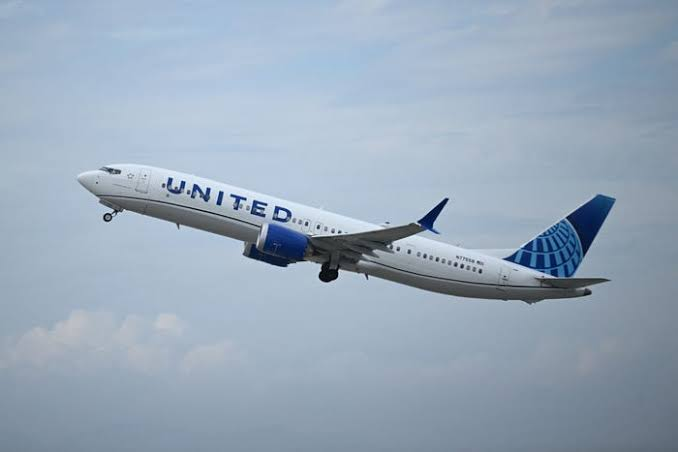

In [ ]:
from PIL import Image

image_path = "/content/images/Airplane2.jpeg"

image = Image.open(image_path).convert("RGB")

display(image)

In [ ]:
question = """1. Is there a bicycle in this image?
2. Describe this image in detail and mention all objects you can see """

prompt = f"USER: <image>\n{question} ASSISTANT:"

inputs = processor_llava(
    text=prompt,
    images=image,
    return_tensors="pt"
).to("cuda", torch.float16)

with torch.inference_mode():
  output = llava.generate(
      **inputs,
      max_new_tokens=150
  )
  answer = processor_llava.decode(
      output[0],
      skip_special_tokens=True
  )
  print(answer)

USER:  
1. Is there a bicycle in this image?
2. Describe this image in detail and mention all objects you can see  ASSISTANT: The image features a large commercial airplane flying through the sky. The airplane is white and blue, and it has a United logo on the side. The airplane is flying high in the sky, and it appears to be a clear day. The airplane is the main focus of the image, and there are no other objects or people visible.


In [ ]:
print(answer)

USER:  
1. Is there a bicycle in this image?
2. Describe this image in detail and mention all objects you can see  ASSISTANT: The image features a large commercial airplane flying through the sky. The airplane is white and blue, and it has a United logo on the side. The airplane is flying high in the sky, and it appears to be a clear day. The airplane is the main focus of the image, and there are no other objects or people visible.


In [ ]:
with open("/content/exercise12_answers.txt", "w") as f:
  f.write("Exercice 12 - Hallucination\n")
  f.write("Image: Airplane.jpeg\n\n")
  f.write("Questions:\n")
  f.write("1. Is there a bicycle in this image?\n")
  f.write("2. Describe this image in detail and mention all objects you can see\n\n")
  f.write("LLaVA Answers:\n")
  f.write(answer +"\n\n")
  f.write("Evaluation : No bicycle hallucination observed. The main object and its description consistent with the image.")
print("Exercice 12 saved successfully !")

Exercice 12 saved successfully !


In [ ]:
from google.colab import files

files.download("/content/exercise12_answers.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Part D — CLIP vs LLaVA

## Exercise 13 — Comparative experiment

Use the same image with both models.

### CLIP

Compare:

- a photo of a cat
- a photo of a dog
- a photo of a horse

### LLaVA

Ask:

> What animal is present in the image? Describe its appearance.

Complete:

| Property | CLIP | LLaVA |
|---|---|---|
| Input |Image + text candidates |Image + text question |
| Main output |Simalarity scores |Natural-language answer |
| Zero-shot classification |Yes |Possible, but not its main purpose |
| Image retrieval |Yes, using embeddings |Not its main purpose |
| Text generation |No |Yes |
| VQA |No, not directly |Yes |
| Open-ended response |No |Yes |

### Questions

**Q33.** Which model is better suited to image classification?  
**Q34.** Which model is better for image description?  
**Q35.** Which model is better for visual question answering?  
**Q36.** Explain the fundamental difference between CLIP and LLaVA.

**Q33. Which model is better suited to image classification?**

CLIP is better suited to image classification because it compares an image with candidate text descriptions and assigns similarity scores. In our experiment, CLIP assigned a score of 99.7% to *"a photo of a cat"*.

**Q34. Which model is better for image description?**

LLaVA is better suited to image description because it generates natural-language responses describing the content of an image. In our experiment, it identified a cat with striped fur sitting on a tree branch.

**Q35. Which model is better for visual question answering?**

LLaVA is better suited to visual question answering because it can answer questions about an image using natural language. CLIP mainly computes similarity scores between images and text and does not directly generate answers.

**Q36. Explain the fundamental difference between CLIP and LLaVA.**

CLIP is a vision-language model designed to align image and text embeddings in a shared space, making it useful for zero-shot classification and semantic image retrieval. LLaVA is a multimodal generative model that combines a vision encoder with a language model to interpret images and generate natural-language answers.

In [ ]:
print("processor:", "processor" in globals())
print("model:", "model" in globals())
print("image:", "image" in globals())
print("device:", "device" in globals())

processor: False
model: False
image: True
device: False


In [ ]:
import torch
from transformers import CLIPProcessor, CLIPModel

device = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_ID = "openai/clip-vit-base-patch32"

processor = CLIPProcessor.from_pretrained(MODEL_ID)
model = CLIPModel.from_pretrained(MODEL_ID).to(device)
model.eval()

print("CLIP loaded:", device)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

CLIP loaded: cuda


In [ ]:
print(image_paths[:10])

['/content/images/Airplane.jpeg', '/content/images/Airplane2.jpeg', '/content/images/Bird1.jpg', '/content/images/Bird2.jpg', '/content/images/Building.jpeg', '/content/images/Car1.jpg', '/content/images/Car2.jpg', '/content/images/Cat (1).jpg', '/content/images/Cat.jpg', '/content/images/Cat2.jpg']


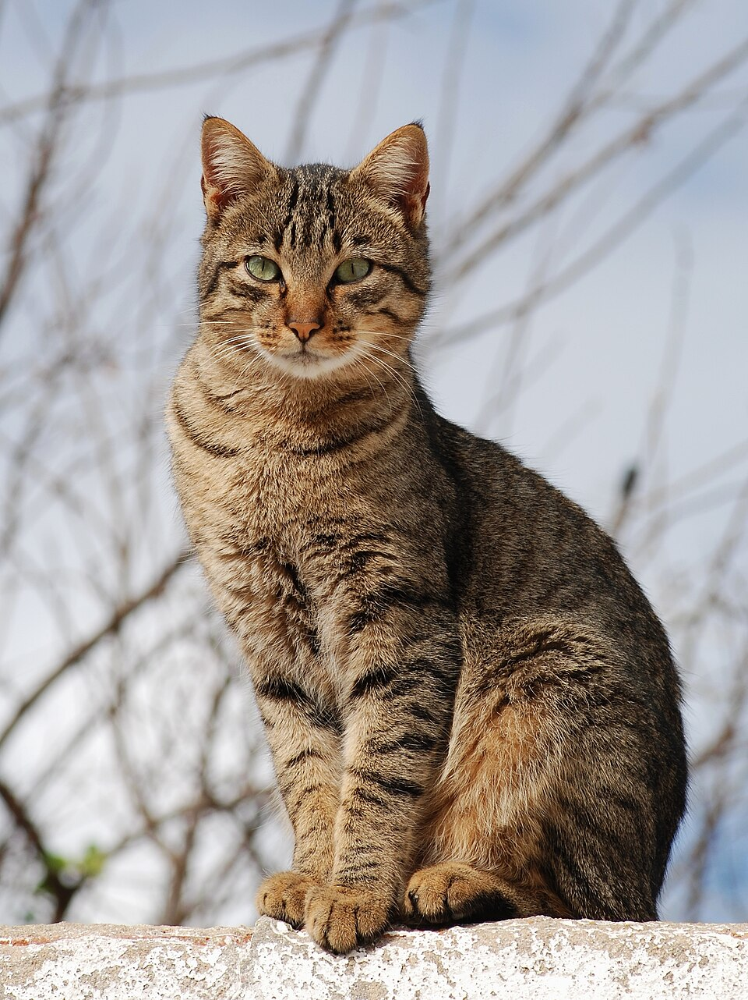

In [ ]:
from PIL import Image

image = Image.open("/content/images/Cat.jpg").convert("RGB")


display(image)

In [ ]:
texts = [
    "a photo of a cat ",
    "a photo of a dog ",
    "a photo of a horse "
]
image_clip = processor(
    text=texts,
    images=image,
    return_tensors="pt",
    padding=True
).to(device)

with torch.inference_mode():
  outputs = model(**image_clip)
  scores = outputs.logits_per_image.softmax(dim=1)[0]
for text, score in zip(texts, scores):
  print(text, ":", round(score.item() *100, 2), "%")

a photo of a cat  : 99.7 %
a photo of a dog  : 0.26 %
a photo of a horse  : 0.03 %


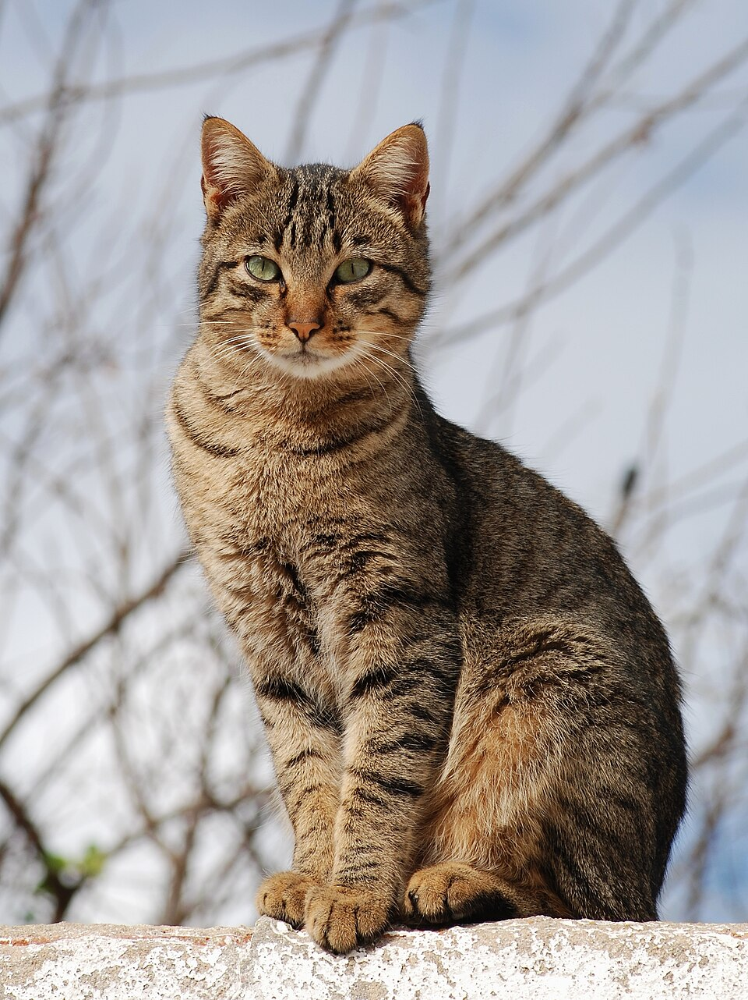

In [ ]:
display(image)

In [ ]:
question = "What animal is present in the image? Describe its appearance."

prompt = f"USER: <image>\n{question} ASSISTANT:"

inputs = processor_llava(
    text=prompt,
    images=image,
    return_tensors="pt"
).to("cuda", torch.float16)

with torch.inference_mode():
  output = llava.generate(
      **inputs,
      max_new_tokens=150
  )
answer = processor_llava.decode(
    output[0],
    skip_special_tokens=True
)
print(answer)

USER:  
What animal is present in the image? Describe its appearance. ASSISTANT: There is a cat present in the image. The cat has a striped pattern on its fur and is sitting on a tree branch.


# Final Mini-Project

Develop a small **Multimodal Image Assistant**.

The application receives:

```text
Image + Question
```

and returns an answer.

### Basic architecture

```text
             IMAGE
               |
               v
        +--------------+
        | Vision Model |
        +------+-------+
               |
               v
        Visual Features
               |
               v
QUESTION ---> LLaVA
               |
               v
             ANSWER
```

### Bonus

Combine CLIP retrieval with LLaVA:

```text
User Query
    |
    v
   CLIP
    |
    v
Top-K Images
    |
    v
  LLaVA
    |
    v
Explanation
```

### Deliverables

1. Jupyter Notebook.
2. Code and outputs for every experiment.
3. CLIP classification accuracy.
4. Top-5 retrieval results.
5. LLaVA VQA results.
6. At least one hallucination example.
7. CLIP/LLaVA comparison.
8. Mini-project.
9. Short conclusion.

In [2]:
import torch

print("PyTorch version :", torch.__version__)
print("CUDA available :", torch.cuda.is_available())

if torch.cuda.is_available():
  print("GPU version :", torch.cuda.get_device_name(0))
else:
  print("Attention: aucun GPU détecté")

PyTorch version : 2.11.0+cu130
CUDA available : True
GPU version : Tesla T4


In [3]:
from google.colab import files

uploaded = files.upload()

Saving images_backup.zip to images_backup.zip


In [5]:
import zipfile
import os

zip_path = "/content/images_backup.zip"
images_dir = "/content/images"

os.makedirs(images_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
  zip_ref.extractall(images_dir)

images = [
    f for f in os.listdir(images_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]
print("Nombre d'images restaurees :", len(images))
print(images)

Nombre d'images restaurees : 22
['sport2.jpg', 'Cat.jpg', 'food.jpeg', 'Bird1.jpg', 'Horse2.jpg', 'Car2.jpg', 'Car1.jpg', 'Horse.jpeg', 'animal.webp', 'people2.jpeg', 'Cat2.jpg', 'landscape3.jpg', 'landscape.jpg', 'animal2.jpg', 'Airplane2.jpeg', 'people.jpg', 'sport.jpg', 'Cat (1).jpg', 'Bird2.jpg', 'Building.jpeg', 'landscape2.webp', 'Airplane.jpeg']


In [7]:
!pip install -q transformers pillow matplotlib

In [9]:
import torch
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_ID = "openai/clip-vit-base-patch32"

processor = CLIPProcessor.from_pretrained(MODEL_ID)
clip_model = CLIPModel.from_pretrained(MODEL_ID).to(device)
clip_model.eval()

print("CLIP loaded")
print("Device :", device)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP loaded
Device : cuda


In [10]:
import os
from PIL import Image

images_dir = "/content/images"

image_paths = sorted([
    os.path.join(images_dir, f)
    for f in os.listdir(images_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])

print("Nombre d'images :", len(image_paths))

for path in image_paths:
  print(os.path.basename(path))

Nombre d'images : 22
Airplane.jpeg
Airplane2.jpeg
Bird1.jpg
Bird2.jpg
Building.jpeg
Car1.jpg
Car2.jpg
Cat (1).jpg
Cat.jpg
Cat2.jpg
Horse.jpeg
Horse2.jpg
animal.webp
animal2.jpg
food.jpeg
landscape.jpg
landscape2.webp
landscape3.jpg
people.jpg
people2.jpeg
sport.jpg
sport2.jpg


In [11]:
import torch
from PIL import Image

image_embeddings = []

for path in image_paths:
  image = Image.open(path).convert("RGB")

  inputs = processor(
      images=image,
      return_tensors="pt"
  ).to(device)

  with torch.no_grad():
    features = clip_model.get_image_features(**inputs)
    if hasattr(features, "pooler_output"):
      features = features.pooler_output
    elif hasattr(features, "image_embeds"):
      features = features.image_embeds

    features = features / features.norm(
        p=2, dim=-1, keepdim=True

    )
  image_embeddings.append(features.squeeze().cpu())

image_embeddings = torch.stack(image_embeddings)

print("Embeddings calcules !")
print("Shape :" , image_embeddings.shape)


Embeddings calcules !
Shape : torch.Size([22, 512])


In [21]:

import torch
import matplotlib.pyplot as plt
from PIL import Image
import os

def search_top5(query, top_k=5):
    # 1. Encoder la requête textuelle
    inputs = processor(
        text=[query],
        return_tensors="pt",
        padding=True
    ).to(device)

    with torch.no_grad():
        text_features = clip_model.get_text_features(**inputs)

        if hasattr(text_features, "pooler_output"):
            text_features = text_features.pooler_output
        elif hasattr(text_features, "text_embeds"):
            text_features = text_features.text_embeds

        text_features = text_features / text_features.norm(
            p=2, dim=-1, keepdim=True
        )

    # 2. Calculer les similarités
    similarities = (
        image_embeddings.to(device) @ text_features.T
    ).squeeze(-1)

    k = min(top_k, len(image_paths))
    scores, indices = torch.topk(similarities, k=k)

    # 3. Afficher les images
    fig, axes = plt.subplots(1, k, figsize=(4 * k, 5))

    if k == 1:
        axes = [axes]

    results = []

    for rank, (score, idx) in enumerate(zip(scores, indices)):
        path = image_paths[idx.item()]
        img = Image.open(path).convert("RGB")

        axes[rank].imshow(img)
        axes[rank].set_title(
            f"{os.path.basename(path)}\nScore: {score.item():.3f}"
        )
        axes[rank].axis("off")

        results.append({
            "rank": rank + 1,
            "image": os.path.basename(path),
            "similarity": round(score.item(), 4)
        })

    plt.tight_layout()
    plt.show()

    return results


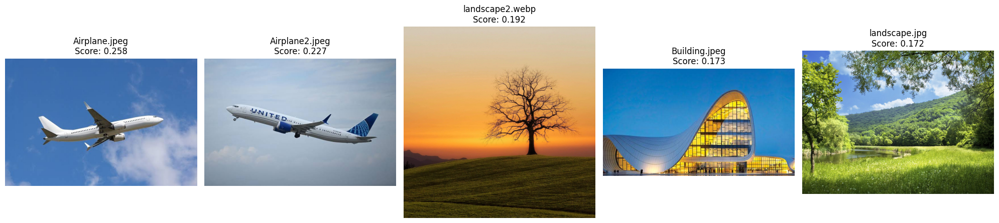

[{'rank': 1, 'image': 'Airplane.jpeg', 'similarity': 0.2576}, {'rank': 2, 'image': 'Airplane2.jpeg', 'similarity': 0.2271}, {'rank': 3, 'image': 'landscape2.webp', 'similarity': 0.1922}, {'rank': 4, 'image': 'Building.jpeg', 'similarity': 0.1734}, {'rank': 5, 'image': 'landscape.jpg', 'similarity': 0.1719}]


In [22]:
results = search_top5("A photo of an airplane flying in the sky", top_k=5)
print(results)

In [23]:

import pandas as pd

df_top5 = pd.DataFrame(results)

df_top5.to_csv(
    "/content/clip_top5_results.csv",
    index=False
)

print(df_top5)
print("\nRésultats sauvegardés !")


   rank            image  similarity
0     1    Airplane.jpeg      0.2576
1     2   Airplane2.jpeg      0.2271
2     3  landscape2.webp      0.1922
3     4    Building.jpeg      0.1734
4     5    landscape.jpg      0.1719

Résultats sauvegardés !


In [24]:

from google.colab import files

files.download("/content/clip_top5_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:

!pip install -q transformers accelerate bitsandbytes


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 29.1 MB/s eta 0:00:00


In [2]:
%pip install -U bitsandbytes accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 28.7 MB/s eta 0:00:00


In [3]:

import torch
import bitsandbytes as bnb

print("PyTorch :", torch.__version__)
print("Bitsandbytes :", bnb.__version__)
print("GPU disponible :", torch.cuda.is_available())


PyTorch : 2.11.0+cu130
Bitsandbytes : 0.50.2
GPU disponible : True


In [1]:
import torch
import bitsandbytes as bnb
import transformers

print("PyTorch :", torch.__version__)
print("bitsandbytes :", bnb.__version__)
print("Transformers :", transformers.__version__)
print("GPU disponible :", torch.cuda.is_available())

PyTorch : 2.11.0+cu130
bitsandbytes : 0.50.2
Transformers : 5.18.0
GPU disponible : True


In [2]:

import torch
import bitsandbytes as bnb

try:
    layer = bnb.nn.Linear4bit(
        16, 8,
        compute_dtype=torch.float16,
        quant_type="nf4"
    ).to("cuda")

    x = torch.randn(2, 16, device="cuda", dtype=torch.float16)
    y = layer(x)

    print("Test bitsandbytes réussi !")
    print("Résultat :", y.shape)

except Exception as e:
    print("Erreur bitsandbytes :", repr(e))


Test bitsandbytes réussi !
Résultat : torch.Size([2, 8])


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (16) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


In [3]:

import torch
from transformers import (
    LlavaForConditionalGeneration,
    AutoProcessor,
    BitsAndBytesConfig
)

MODEL_ID = "llava-hf/llava-1.5-7b-hf"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4"
)

processor_llava = AutoProcessor.from_pretrained(MODEL_ID)

llava = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=quantization_config,
    device_map="auto",
    torch_dtype=torch.float16
)

print("LLaVA chargé avec succès !")


model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

LLaVA chargé avec succès !


In [4]:

import os

print("Dossier images présent :", os.path.exists("/content/images"))


Dossier images présent : False


In [5]:

from google.colab import files

uploaded = files.upload()


Saving images_backup.zip to images_backup.zip


In [6]:

import os
import zipfile

zip_path = "/content/images_backup.zip"
image_dir = "/content/images"

os.makedirs(image_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(image_dir)

images = [
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
]

print("Nombre d'images restaurées :", len(images))
print("Airplane.jpeg présent :", "Airplane.jpeg" in images)


Nombre d'images restaurées : 22
Airplane.jpeg présent : True


In [7]:

from PIL import Image
import torch

image_path = "/content/images/Airplane.jpeg"
image = Image.open(image_path).convert("RGB")

question = "Describe the airplane in this image."

prompt = (
    "USER: <image>\n"
    + question
    + "\nASSISTANT:"
)

inputs = processor_llava(
    text=prompt,
    images=image,
    return_tensors="pt"
).to("cuda", torch.float16)

with torch.no_grad():
    output = llava.generate(
        **inputs,
        max_new_tokens=100
    )

answer = processor_llava.decode(
    output[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
)

print("Question :", question)
print("Réponse de LLaVA :", answer)


Question : Describe the airplane in this image.
Réponse de LLaVA : The airplane in the image is a large white jetliner, likely a commercial airplane, flying through the sky. It has two engines on each wing, and the tail of the plane is visible in the sky. The airplane is flying high in the blue sky, showcasing its impressive size and design.


In [8]:

import torch
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_ID_CLIP = "openai/clip-vit-base-patch32"

processor = CLIPProcessor.from_pretrained(MODEL_ID_CLIP)
clip_model = CLIPModel.from_pretrained(MODEL_ID_CLIP).to(device)
clip_model.eval()

print("CLIP chargé avec succès !")


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP chargé avec succès !


In [9]:

import os
import torch
from PIL import Image

image_dir = "/content/images"

image_paths = sorted([
    os.path.join(image_dir, f)
    for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
])

image_embeddings = []

for path in image_paths:
    image = Image.open(path).convert("RGB")

    inputs = processor(
        images=image,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        features = clip_model.get_image_features(**inputs)

        if hasattr(features, "pooler_output"):
            features = features.pooler_output
        elif hasattr(features, "image_embeds"):
            features = features.image_embeds

        features = features / features.norm(
            p=2, dim=-1, keepdim=True
        )

    image_embeddings.append(features.squeeze(0).cpu())

image_embeddings = torch.stack(image_embeddings)

print("Nombre d'images :", len(image_paths))
print("Shape des embeddings :", image_embeddings.shape)


Nombre d'images : 22
Shape des embeddings : torch.Size([22, 512])


In [11]:

import torch
import matplotlib.pyplot as plt
from PIL import Image
import os

def search_top5(query, top_k=5):
    inputs = processor(
        text=[query],
        return_tensors="pt",
        padding=True
    ).to(device)

    with torch.no_grad():
        text_features = clip_model.get_text_features(**inputs)

        if hasattr(text_features, "pooler_output"):
            text_features = text_features.pooler_output
        elif hasattr(text_features, "text_embeds"):
            text_features = text_features.text_embeds

        text_features = text_features / text_features.norm(
            p=2, dim=-1, keepdim=True
        )

    similarities = (
        image_embeddings.to(device) @ text_features.T
    ).squeeze(-1)

    k = min(top_k, len(image_paths))
    scores, indices = torch.topk(similarities, k=k)

    results = []
    fig, axes = plt.subplots(1, k, figsize=(4 * k, 5))

    if k == 1:
        axes = [axes]

    for rank, (score, idx) in enumerate(zip(scores, indices)):
        path = image_paths[idx.item()]
        img = Image.open(path).convert("RGB")

        axes[rank].imshow(img)
        axes[rank].set_title(
            f"{os.path.basename(path)}\nScore: {score.item():.3f}"
        )
        axes[rank].axis("off")

        results.append({
            "rank": rank + 1,
            "image": os.path.basename(path),
            "similarity": round(score.item(), 4)
        })

    plt.tight_layout()
    plt.show()

    return results


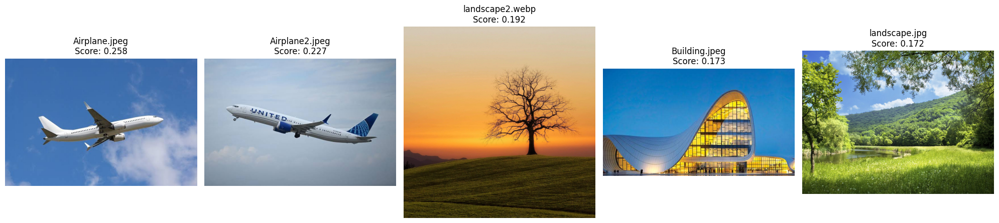

{'rank': 1, 'image': 'Airplane.jpeg', 'similarity': 0.2576}
{'rank': 2, 'image': 'Airplane2.jpeg', 'similarity': 0.2271}
{'rank': 3, 'image': 'landscape2.webp', 'similarity': 0.1922}
{'rank': 4, 'image': 'Building.jpeg', 'similarity': 0.1734}
{'rank': 5, 'image': 'landscape.jpg', 'similarity': 0.1719}


In [12]:

results = search_top5(
    "A photo of an airplane flying in the sky",
    top_k=5
)

for result in results:
    print(result)


In [13]:

from PIL import Image
import torch
import os

# 1. Récupérer la meilleure image sélectionnée par CLIP
selected_name = results[0]["image"]
selected_path = os.path.join("/content/images", selected_name)

image = Image.open(selected_path).convert("RGB")

# 2. Poser une question à LLaVA
question = "Describe the objects and the scene in this image."

prompt = (
    "USER: <image>\n"
    + question
    + "\nASSISTANT:"
)

# 3. Préparer l'image et le texte
inputs = processor_llava(
    text=prompt,
    images=image,
    return_tensors="pt"
).to("cuda", torch.float16)

# 4. Générer la réponse
with torch.no_grad():
    output = llava.generate(
        **inputs,
        max_new_tokens=120
    )

answer = processor_llava.decode(
    output[0][inputs["input_ids"].shape[1]:],
    skip_special_tokens=True
)

# 5. Afficher le résultat final
print("Requête CLIP : A photo of an airplane flying in the sky")
print("Image sélectionnée :", selected_name)
print("Score CLIP :", results[0]["similarity"])
print("Question :", question)
print("Réponse LLaVA :", answer)


Requête CLIP : A photo of an airplane flying in the sky
Image sélectionnée : Airplane.jpeg
Score CLIP : 0.2576
Question : Describe the objects and the scene in this image.
Réponse LLaVA : The image features a large white airplane flying high in the sky. The airplane is the main focus of the scene, occupying a significant portion of the image. The sky is blue, providing a clear backdrop for the airplane. The airplane appears to be ascending, as it is flying upwards.


In [14]:

%pip install -q gradio


In [15]:

import gradio as gr
import os
import torch
from PIL import Image

def multimodal_assistant(query, question, selected_index):
    # Recherche des images avec CLIP
    search_results = search_top5(query, top_k=5)

    # Sélection de l'image choisie
    index = int(selected_index)
    selected_name = search_results[index]["image"]
    selected_path = os.path.join("/content/images", selected_name)
    image = Image.open(selected_path).convert("RGB")

    # Préparer la question pour LLaVA
    prompt = (
        "USER: <image>\n"
        + question
        + "\nASSISTANT:"
    )

    inputs = processor_llava(
        text=prompt,
        images=image,
        return_tensors="pt"
    ).to("cuda", torch.float16)

    with torch.no_grad():
        output = llava.generate(
            **inputs,
            max_new_tokens=120
        )

    answer = processor_llava.decode(
        output[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return selected_path, answer, search_results


with gr.Blocks(title="Multimodal Image Assistant") as demo:
    gr.Markdown("# Multimodal Image Assistant")
    gr.Markdown("Search images with CLIP and ask questions with LLaVA.")

    query = gr.Textbox(
        label="Image search query",
        value="A photo of an airplane flying in the sky"
    )

    question = gr.Textbox(
        label="Question about the image",
        value="Describe the objects and the scene in this image."
    )

    selected_index = gr.Radio(
        choices=["0", "1", "2", "3", "4"],
        value="0",
        label="Choose a retrieved image (0 = Top-1)"
    )

    run_button = gr.Button("Search and answer")

    selected_image = gr.Image(label="Selected image")
    answer_output = gr.Textbox(label="LLaVA answer")
    results_output = gr.JSON(label="CLIP Top-5 results")

    run_button.click(
        fn=multimodal_assistant,
        inputs=[query, question, selected_index],
        outputs=[selected_image, answer_output, results_output]
    )

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cb6ba22cbfa965e70e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [16]:

import pandas as pd
from google.colab import files

df_top5 = pd.DataFrame(results)

df_top5.to_csv(
    "/content/clip_top5_results.csv",
    index=False
)

files.download("/content/clip_top5_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:

import json
from google.colab import files

with open("/content/clip_top5_results.json", "w") as f:
    json.dump(results, f, indent=4)

files.download("/content/clip_top5_results.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:

import shutil
from google.colab import files

shutil.make_archive(
    "/content/images_backup_final",
    "zip",
    "/content/images"
)

files.download("/content/images_backup_final.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:

import os

print("Dossier images :", os.path.exists("/content/images"))
print("CLIP chargé :", "clip_model" in globals())
print("Processor chargé :", "processor" in globals())
print("Embeddings présents :", "image_embeddings" in globals())
print("Résultats Top-5 présents :", "results" in globals())


Dossier images : False
CLIP chargé : False
Processor chargé : False
Embeddings présents : False
Résultats Top-5 présents : False
